# Polynomial and interaction features

Polynomial expansion creates powers and interactions such as x² and x1 × x2. These features allow a linear model to represent curves and combined effects. This notebook uses house quality and living area to demonstrate the idea.

## Why create polynomial features?

A linear model draws a flat line or plane. House prices often rise non-linearly with living area and quality. Adding a squared term or an interaction gives the linear model extra shapes without changing the estimator itself.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.linear_model import LinearRegression,Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
sns.set_theme(style='whitegrid',context='notebook')

candidates=[Path('feature-engineering/imputation/houseprice.csv'),Path('../imputation/houseprice.csv'),Path('houseprice.csv')]
path=next((p for p in candidates if p.exists()),None)
if path is None: raise FileNotFoundError('Place houseprice.csv in feature-engineering/imputation/.')
data=pd.read_csv(path,na_values=['NA'])
model_data=data[['GrLivArea','OverallQual','SalePrice']].dropna().copy()
X=model_data[['GrLivArea','OverallQual']]; y=model_data['SalePrice']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=42)
model_data.head()

,GrLivArea,OverallQual,SalePrice
0,1710,7,208500
1,1262,6,181500
2,1786,7,223500
3,1717,7,140000
4,2198,8,250000


## 1. Inspect the expansion

With two input variables and degree 2, the transformer creates the original terms, squared terms, and their interaction. The number of columns grows quickly with degree and input count, so start small.

In [2]:
expander=PolynomialFeatures(degree=2,include_bias=False)
expanded=expander.fit_transform(X_train)
display(pd.DataFrame(expanded,columns=expander.get_feature_names_out(X_train.columns)).head())
print('Original columns:',X_train.shape[1])
print('Expanded columns:',expanded.shape[1])

,GrLivArea,OverallQual,GrLivArea^2,GrLivArea OverallQual,OverallQual^2
0,1314.0,5.0,1726596.0,6570.0,25.0
1,1571.0,6.0,2468041.0,9426.0,36.0
2,796.0,5.0,633616.0,3980.0,25.0
3,1768.0,5.0,3125824.0,8840.0,25.0
4,1691.0,5.0,2859481.0,8455.0,25.0


Original columns: 2
Expanded columns: 5


## 2. Compare a linear baseline with a polynomial model

The polynomial transformer belongs inside the pipeline. That ensures its fitted feature layout is reproduced on test and future data. Ridge regularisation helps control the correlation and larger feature set created by expansion.

In [3]:
linear=Pipeline([('scale',StandardScaler()),('model',LinearRegression())])
polynomial=Pipeline([('poly',PolynomialFeatures(degree=2,include_bias=False)),('scale',StandardScaler()),('model',Ridge(alpha=10.0))])
models={'Linear baseline':linear,'Degree-2 Ridge':polynomial}
results=[]
for name,model in models.items():
    model.fit(X_train,y_train)
    pred=model.predict(X_test)
    results.append({'model':name,'MAE':mean_absolute_error(y_test,pred),'RMSE':np.sqrt(mean_squared_error(y_test,pred)),'R2':r2_score(y_test,pred)})
display(pd.DataFrame(results).set_index('model').round(2))

,MAE,RMSE,R2
model,,,
Linear baseline,28555.25,44159.60,0.75
Degree-2 Ridge,25686.31,40012.18,0.79


## 3. Visualise the polynomial model

A better validation score is useful evidence, but inspect predictions and residuals as well. If the polynomial model improves training but not test performance, it may be overfitting.

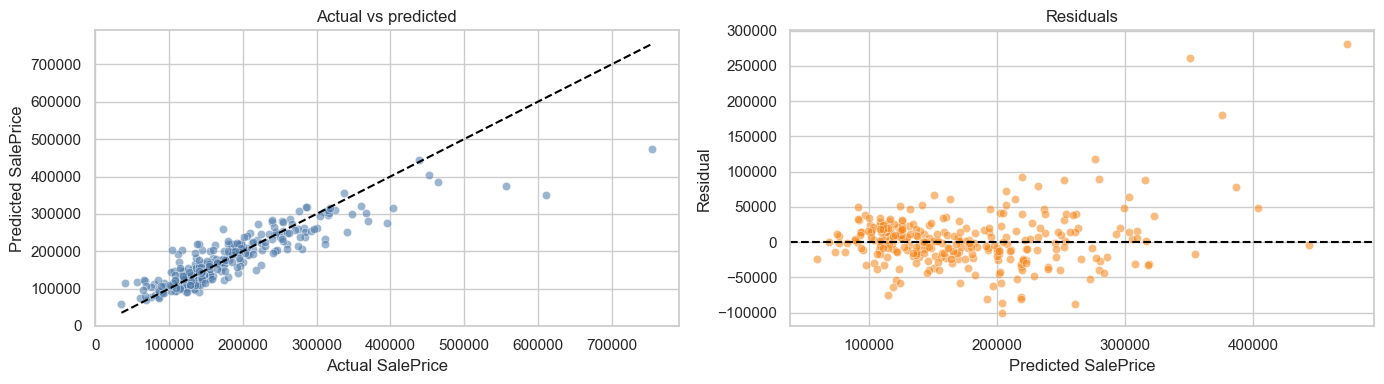

In [4]:
polynomial.fit(X_train,y_train)
pred=polynomial.predict(X_test)
residual=y_test-pred
fig,axes=plt.subplots(1,2,figsize=(14,4))
sns.scatterplot(x=y_test,y=pred,alpha=.55,color='#4C78A8',ax=axes[0]); lo=min(y_test.min(),pred.min()); hi=max(y_test.max(),pred.max()); axes[0].plot([lo,hi],[lo,hi],'--',color='black'); axes[0].set(xlabel='Actual SalePrice',ylabel='Predicted SalePrice',title='Actual vs predicted')
sns.scatterplot(x=pred,y=residual,alpha=.55,color='#F58518',ax=axes[1]); axes[1].axhline(0,color='black',linestyle='--'); axes[1].set(xlabel='Predicted SalePrice',ylabel='Residual',title='Residuals')
plt.tight_layout(); plt.show()

## Choosing the degree

Degree 2 is usually a sensible first experiment. Higher degrees create many terms, increase multicollinearity, and can produce wild behaviour outside the training range. Use cross-validation and regularisation to choose degree and strength rather than selecting the most flexible model by training score.

## Summary

PolynomialFeatures gives a linear model access to curves and interactions. It can be useful when a domain relationship is smooth and low-dimensional, but feature growth and overfitting mean that a simple baseline and validation comparison are essential.